# Lab 3 – Image Classification (CIFAR-10)
**ESIEA x SKEMA – SO Mathys, HOEGY Victor, ANDRIAMANAMIRIJA Fenosoa - Deep Learning (AI_INF5018)**

Goal: build a custom convolutional neural network (CNN) to classify the CIFAR-10 images, then compare with two pretrained ImageNet models (MobileNetV2 and ResNet50).

Files handed in:
- `SO_HOEGY_ANDRIAMANAMIRIJA.keras` – the trained model (Question 6)
- `train_cnn.py` – the training script (Question 8)
- this notebook – answers to Questions **3, 7, 9 and 12** are marked with ⭐

In [1]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.0


## Part 1 – Custom model

### Question 1 – Load CIFAR-10

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
print("train:", x_train.shape, y_train.shape)
print("test :", x_test.shape, y_test.shape)
print("pixel range:", x_train.min(), "-", x_train.max())

train: (50000, 32, 32, 3) (50000, 1)
test : (10000, 32, 32, 3) (10000, 1)
pixel range: 0 - 255


CIFAR-10 contains **50,000 training** and **10,000 test** colour images of size **32 × 32 × 3**, split into **10 balanced classes** (5,000 training images per class).

### Question 2 – One-hot encoding of the labels

In [3]:
y_train_int, y_test_int = y_train.ravel(), y_test.ravel()   # keep integer labels for display
y_train_oh = keras.utils.to_categorical(y_train_int, 10)
y_test_oh  = keras.utils.to_categorical(y_test_int, 10)
print("label", y_train_int[0], "->", y_train_oh[0])

label 6 -> [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


Each label becomes a vector of 10 values with a single 1 at the class index. This matches the 10-unit softmax output of the network and the `categorical_crossentropy` loss.

### ⭐ Question 3 – First 9 images and their labels

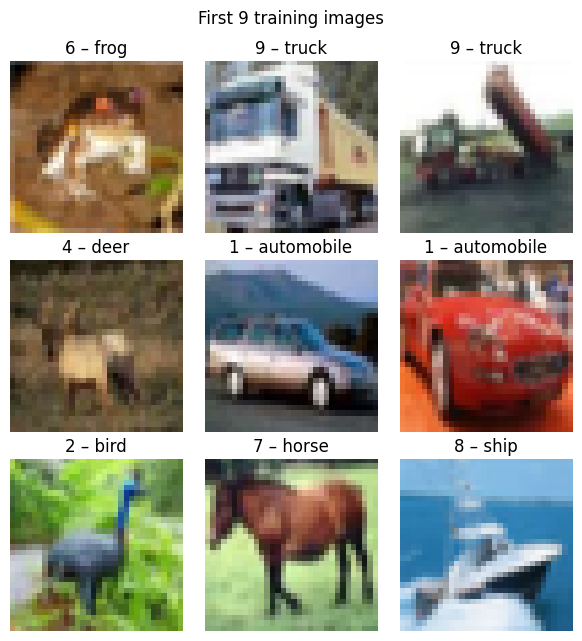

In [4]:
labels = {0:'airplane',1:'automobile',2:'bird',3:'cat',4:'deer',5:'dog',
          6:'frog',7:'horse',8:'ship',9:'truck'}

fig, axes = plt.subplots(3, 3, figsize=(6, 6.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i])
    ax.set_title(f"{y_train_int[i]} – {labels[y_train_int[i]]}")
    ax.axis("off")
plt.suptitle("First 9 training images"); plt.tight_layout(); plt.show()

**Answer.** The first nine training images are shown with their label number and name. The images are very small (32 × 32 pixels): the object is often recognisable only by its overall shape and colour, it is not always centred, and the background varies a lot. This is why CIFAR-10 is much harder than MNIST, and why a convolutional network is needed.

### Question 4 – Normalisation

In [5]:
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
print("train range:", x_train.min(), "-", x_train.max(), "| test range:", x_test.min(), "-", x_test.max())

train range: 0.0 - 1.0 | test range: 0.0 - 1.0


Pixels go from [0, 255] to [0, 1]. Inputs on a small, common scale keep the activations and gradients well-behaved, so training is faster and more stable. The same transformation (divide by 255) is applied to train and test.

### Question 5 – Custom CNN

**Validation set.** We hold out the last 5,000 training images as a **validation set**. All design choices (architecture, dropout rates, number of epochs, learning-rate schedule) were driven by the validation score. The test set is used only once, at the very end, to report the final accuracy.

**Architecture** (VGG-style: stacks of small 3×3 convolutions, filters doubling at each stage):

| Stage | Layers | Output |
|---|---|---|
| Augmentation | random horizontal flip, random translation ±10 % | 32×32×3 |
| Block 1 | 2 × [Conv 3×3, 32 filters → BatchNorm → ReLU] → MaxPool → Dropout 0.2 | 16×16×32 |
| Block 2 | 2 × [Conv 3×3, 64 filters → BatchNorm → ReLU] → MaxPool → Dropout 0.3 | 8×8×64 |
| Block 3 | 2 × [Conv 3×3, 128 filters → BatchNorm → ReLU] → MaxPool → Dropout 0.4 | 4×4×128 |
| Head | Flatten → Dense 128 → BatchNorm → ReLU → Dropout 0.5 → Dense 10 softmax | 10 |

**Techniques used and why:**
- **Batch normalisation** (allowed by the lab): normalises each layer's activations over the mini-batch, which stabilises and speeds up training and allows a higher learning rate. The convolutions have no bias because the BatchNorm shift plays that role.
- **Dropout** (allowed by the lab): randomly sets a fraction of the activations to 0 during training, so the network cannot rely on a few specific neurons. The rate increases with depth, where the layers have more parameters and overfit more.
- **Data augmentation** (extra technique, sources below): each training image is randomly flipped left/right and shifted by up to 10 % at every epoch. A flipped or slightly shifted cat is still a cat, so the network sees "new" plausible images and generalises better. These layers are only active during training; at prediction time they do nothing.
- **Learning-rate reduction and early stopping** (Keras callbacks): the learning rate is halved when the validation loss stops improving for 3 epochs, and training stops after 8 epochs without improvement, keeping the best weights.

**Sources for data augmentation:**
- C. Shorten & T. M. Khoshgoftaar, "A survey on Image Data Augmentation for Deep Learning", *Journal of Big Data*, 6, 60 (2019).
- Keras documentation, image augmentation layers: `RandomFlip`, `RandomTranslation` (https://keras.io/api/layers/preprocessing_layers/image_augmentation/).

In [6]:
VAL_SIZE = 5000
x_tr, y_tr = x_train[:-VAL_SIZE], y_train_oh[:-VAL_SIZE]
x_val, y_val = x_train[-VAL_SIZE:], y_train_oh[-VAL_SIZE:]

def conv_block(x, filters, dropout):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(dropout)(x)

def build_model():
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomTranslation(0.1, 0.1, fill_mode="reflect")(x)
    x = conv_block(x, 32, 0.2)
    x = conv_block(x, 64, 0.3)
    x = conv_block(x, 128, 0.4)
    x = layers.Flatten()(x)
    x = layers.Dense(128, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="cifar10_cnn")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_model()
model.summary()

Model: "cifar10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [7]:
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
]
history = model.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                    epochs=30, batch_size=64, callbacks=callbacks, verbose=2)

Epoch 1/30


704/704 - 174s - 247ms/step - accuracy: 0.3889 - loss: 1.7073 - val_accuracy: 0.4636 - val_loss: 1.5053 - learning_rate: 0.0010


Epoch 2/30


704/704 - 144s - 205ms/step - accuracy: 0.5394 - loss: 1.2795 - val_accuracy: 0.6362 - val_loss: 1.0176 - learning_rate: 0.0010


Epoch 3/30


704/704 - 144s - 205ms/step - accuracy: 0.6163 - loss: 1.0901 - val_accuracy: 0.6040 - val_loss: 1.1072 - learning_rate: 0.0010


... (50 outputs left out)

Epoch 29/30


704/704 - 158s - 224ms/step - accuracy: 0.8524 - loss: 0.4342 - val_accuracy: 0.8660 - val_loss: 0.3867 - learning_rate: 1.2500e-04


Epoch 30/30


704/704 - 158s - 224ms/step - accuracy: 0.8536 - loss: 0.4310 - val_accuracy: 0.8700 - val_loss: 0.3779 - learning_rate: 1.2500e-04


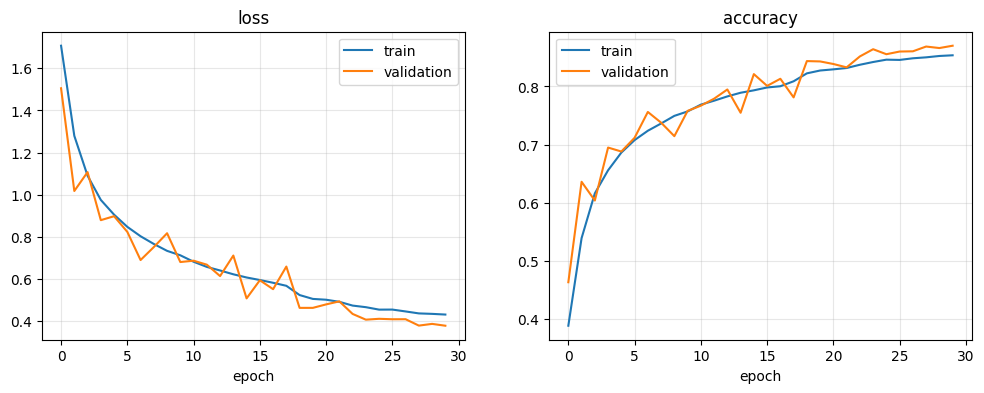

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key in zip(axes, ["loss", "accuracy"]):
    ax.plot(history.history[key], label="train")
    ax.plot(history.history["val_" + key], label="validation")
    ax.set_xlabel("epoch"); ax.set_title(key); ax.grid(alpha=.3); ax.legend()
plt.show()

In [9]:
val_loss, val_acc = model.evaluate(x_val, y_val, verbose=0)
test_loss, test_acc = model.evaluate(x_test, y_test_oh, verbose=0)
print(f"validation accuracy: {val_acc:.4f}")
print(f"TEST accuracy      : {test_acc:.4f}")

validation accuracy: 0.8700
TEST accuracy      : 0.8641


**Result.** After 30 epochs, the CNN reaches **87.0 % validation accuracy** and **86.4 % test accuracy**, well above the 70 % target.

Reading the curves:
- The training accuracy (85.4 %) stays slightly **below** the validation accuracy. This is expected and is a sign that there is no overfitting: during training, the images are augmented and half of the dense neurons are dropped, which makes the task harder; at evaluation time, the network uses clean images and all its neurons.
- The validation curve is noisy in the first epochs (learning rate 10⁻³), then becomes smoother and keeps improving each time `ReduceLROnPlateau` halves the learning rate (epochs 19, 23 and 28).
- Early stopping never triggered: the validation loss was still decreasing slightly at epoch 30. A few more epochs would probably gain a little more, but training on CPU costs about 2.5 minutes per epoch, so we stopped at 30.

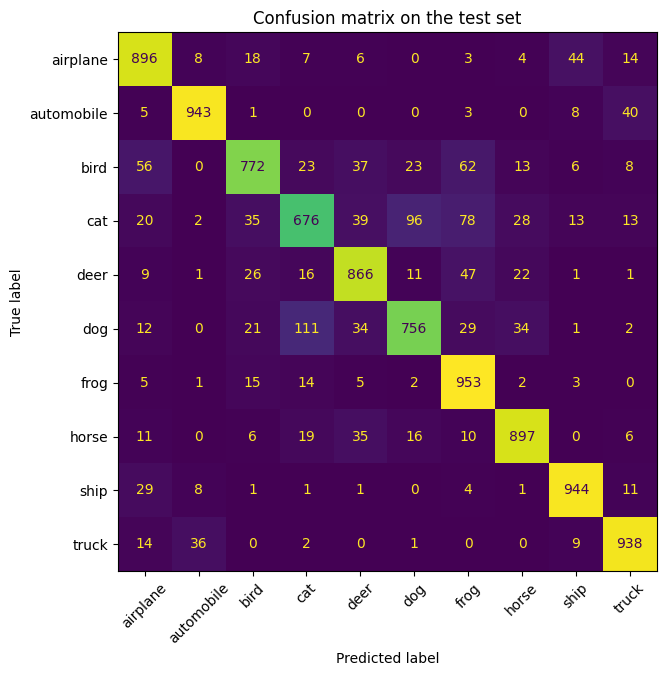

  airplane: 89.6%
automobile: 94.3%
      bird: 77.2%
       cat: 67.6%
      deer: 86.6%
       dog: 75.6%
      frog: 95.3%
     horse: 89.7%
      ship: 94.4%
     truck: 93.8%


In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_pred_int = model.predict(x_test, verbose=0).argmax(axis=1)
cm = confusion_matrix(y_test_int, y_pred_int)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=list(labels.values())).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix on the test set"); plt.show()
for k, name in labels.items():
    print(f"{name:>10}: {cm[k, k] / cm[k].sum():.1%}")

The confusion matrix shows where the model struggles. Vehicles and frogs are recognised very well (automobile, ship, truck, frog ≥ 93 %). The hardest classes are **cat (67.6 %)** and **dog (75.6 %)**, which are mostly confused with each other: at 32 × 32 pixels, a cat and a dog have very similar shapes, colours and textures. Bird (77 %) is also harder, often confused with other animals (deer, frog, airplane against the sky).

### Question 6 – Save the model

In [11]:
MODEL_PATH = "SO_HOEGY_ANDRIAMANAMIRIJA.keras"
model.save(MODEL_PATH)
reloaded = keras.models.load_model(MODEL_PATH)
print("saved:", MODEL_PATH, f"({os.path.getsize(MODEL_PATH)/1e6:.1f} MB)")
print("reloaded test accuracy:", round(reloaded.evaluate(x_test, y_test_oh, verbose=0)[1], 4))

saved: SO_HOEGY_ANDRIAMANAMIRIJA.keras (6.8 MB)


reloaded test accuracy: 0.8641


### ⭐ Question 7 – First 4 test images: predicted vs. true labels

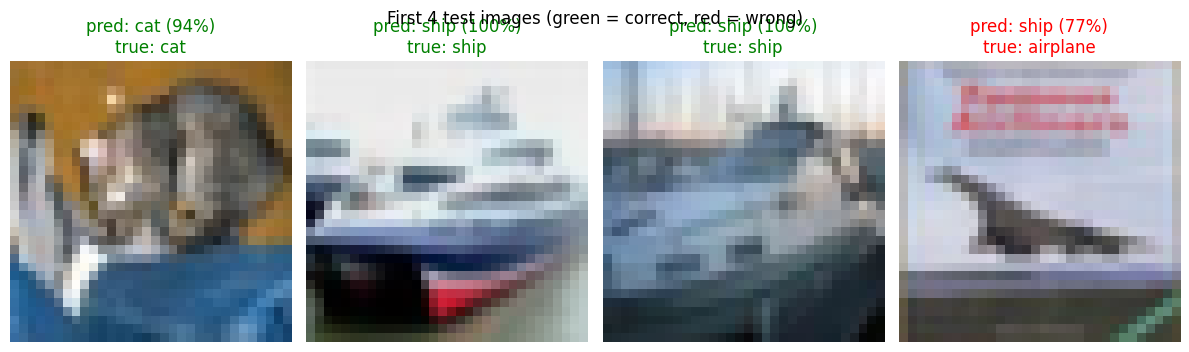

In [12]:
probs = model.predict(x_test[:4], verbose=0)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6))
for i, ax in enumerate(axes):
    pred, true = probs[i].argmax(), y_test_int[i]
    ax.imshow(x_test[i]); ax.axis("off")
    ax.set_title(f"pred: {labels[pred]} ({probs[i].max():.0%})\ntrue: {labels[true]}",
                 color="green" if pred == true else "red")
plt.suptitle("First 4 test images (green = correct, red = wrong)"); plt.tight_layout(); plt.show()

**Answer.** On the first four test images, the model gets **3 out of 4 right**:
- image 0: predicted **cat** (94 %), true cat ✔
- image 1: predicted **ship** (100 %), true ship ✔
- image 2: predicted **ship** (99.7 %), true ship ✔
- image 3: predicted **ship** (77 %), true **airplane** ✘

The mistake is understandable: image 3 is a plane shown against a uniform blue-grey background. The network has learnt that a grey elongated object surrounded by a blue, uniform area is very often a ship on the sea, so it confuses the sky with water. Its confidence is also clearly lower (77 %) than for the correct predictions (≥ 94 %).

### Question 8 – Training script

The script [`train_cnn.py`](train_cnn.py) takes no input, loads CIFAR-10, builds **exactly the same CNN** as above, trains it on the training data only (with the same 5,000-image validation split taken from the training set) and saves it as `SO_HOEGY_ANDRIAMANAMIRIJA.keras`. The test set is never loaded into a variable in that script:

```bash
python train_cnn.py
```

### ⭐ Question 9 – Why would the accuracy on another test set most probably be lower?

**Answer.** The test accuracy of Question 5 is an **optimistic** estimate, for several reasons:

1. **The model was selected on this data.** We tried several architectures, dropout rates and training settings and kept the one that scored best. Even though we used a validation set for most choices, the final model is the "winner" among many tries, and looking at the test score at all influenced what we kept. Part of its score therefore comes from luck on these particular 10,000 images: on new images, that lucky part does not carry over (this is a selection bias, the same idea as overfitting, but at the level of the hyperparameters instead of the weights).
2. **Sampling noise.** 10,000 images is a finite sample. With an accuracy around p ≈ 0.85, the standard error is √(p(1−p)/n) ≈ 0.36 %, so another test set would give a score a few tenths of a point higher or lower just by chance. Since we kept the model that looked best on our set, the error tends to go in the unfavourable direction.
3. **Distribution shift.** CIFAR-10's test images were collected and labelled exactly like the training images (same sources, same 32 × 32 size, same centring). A new test set taken elsewhere (other cameras, lighting, framing, image quality) would not follow exactly the same distribution, and CNNs are known to lose accuracy under such shifts. A well-known example: Recht et al. (2018), *Do CIFAR-10 Classifiers Generalize to CIFAR-10?*, built a new test set following the same protocol and observed a drop of several points for most models.

So a second test set would most likely give a lower accuracy than the one we reported.

## Part 2 – Pretrained models (MobileNetV2 and ResNet50)

Both models are trained on **ImageNet** (1.2 million images, **1,000 classes**). We load them with their ImageNet weights and their classification head (`include_top=True`), so they predict ImageNet classes directly.

### Question 10 – Load the models and find their input size

In [13]:
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications import mobilenet_v2, resnet50

mobilenet = MobileNetV2(weights="imagenet")
resnet = ResNet50(weights="imagenet")
for name, m in [("MobileNetV2", mobilenet), ("ResNet50", resnet)]:
    print(f"{name:12s} input shape: {m.input_shape} | output: {m.output_shape} | params: {m.count_params():,}")

MobileNetV2  input shape: (None, 224, 224, 3) | output: (None, 1000) | params: 3,538,984
ResNet50     input shape: (None, 224, 224, 3) | output: (None, 1000) | params: 25,636,712


Both networks accept **224 × 224 × 3** RGB images (the `None` dimension is the batch size) and output a probability for each of the **1,000 ImageNet classes**. MobileNetV2 is much lighter (~3.5 M parameters) than ResNet50 (~25.6 M parameters).

### Question 11 – Load the test images and preprocess them

We use the first 12 CIFAR-10 test images (raw pixels, before our own normalisation). Two steps are needed for each model:
1. **Resize** from 32 × 32 to 224 × 224 (bilinear interpolation). We cannot add information that is not there: the images become larger but stay blurry.
2. Apply the model's own **`preprocess_input`**, which reproduces the preprocessing used during the ImageNet training:
   - MobileNetV2: pixels scaled to [−1, 1];
   - ResNet50: RGB → BGR and subtraction of the ImageNet mean of each channel (no scaling).

MobileNetV2 input: (12, 224, 224, 3) range [-1.00, 1.00]
ResNet50 input   : (12, 224, 224, 3) range [-123.7, 151.1]


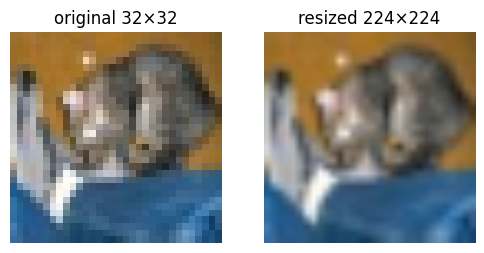

In [14]:
N = 12
raw = (x_test[:N] * 255.0).astype("float32")          # back to [0, 255], the format expected by preprocess_input
resized = tf.image.resize(raw, (224, 224), method="bilinear").numpy()

x_mobilenet = mobilenet_v2.preprocess_input(resized.copy())
x_resnet = resnet50.preprocess_input(resized.copy())
print("MobileNetV2 input:", x_mobilenet.shape, f"range [{x_mobilenet.min():.2f}, {x_mobilenet.max():.2f}]")
print("ResNet50 input   :", x_resnet.shape, f"range [{x_resnet.min():.1f}, {x_resnet.max():.1f}]")

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(x_test[0]); axes[0].set_title("original 32×32")
axes[1].imshow(resized[0] / 255.0); axes[1].set_title("resized 224×224")
for ax in axes: ax.axis("off")
plt.show()

### ⭐ Question 12 – Predictions of both models

In [15]:
decode = keras.applications.imagenet_utils.decode_predictions
pred_mobilenet = decode(mobilenet.predict(x_mobilenet, verbose=0), top=3)
pred_resnet = decode(resnet.predict(x_resnet, verbose=0), top=3)

fmt = lambda preds: ", ".join(f"{label} ({p:.0%})" for _, label, p in preds)
for i in range(N):
    print(f"[{i:2d}] true: {labels[y_test_int[i]]}")
    print(f"     MobileNetV2: {fmt(pred_mobilenet[i])}")
    print(f"     ResNet50   : {fmt(pred_resnet[i])}")

    0/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


[ 0] true: cat
     MobileNetV2: fox_squirrel (40%), hamster (14%), polecat (13%)
     ResNet50   : triceratops (11%), marmoset (9%), Sealyham_terrier (8%)
[ 1] true: ship
     MobileNetV2: milk_can (17%), iron (15%), cowboy_hat (5%)
     ResNet50   : speedboat (96%), trimaran (1%), yawl (1%)
[ 2] true: ship
     MobileNetV2: amphibian (83%), milk_can (3%), bulletproof_vest (1%)
     ResNet50   : amphibian (39%), moving_van (23%), convertible (5%)
[ 3] true: airplane
     MobileNetV2: screen (16%), weasel (14%), platypus (5%)
     ResNet50   : moving_van (22%), book_jacket (7%), safe (7%)
[ 4] true: frog
     MobileNetV2: three-toed_sloth (54%), fox_squirrel (4%), proboscis_monkey (3%)
     ResNet50   : vine_snake (24%), tailed_frog (13%), wood_rabbit (13%)
[ 5] true: frog
     MobileNetV2: lion (12%), kit_fox (8%), redbone (5%)
     ResNet50   : patas (37%), marmoset (18%), orangutan (7%)
[ 6] true: automobile
     MobileNetV2: racer (24%), chain_saw (17%), moving_van (4%)
     ResNet

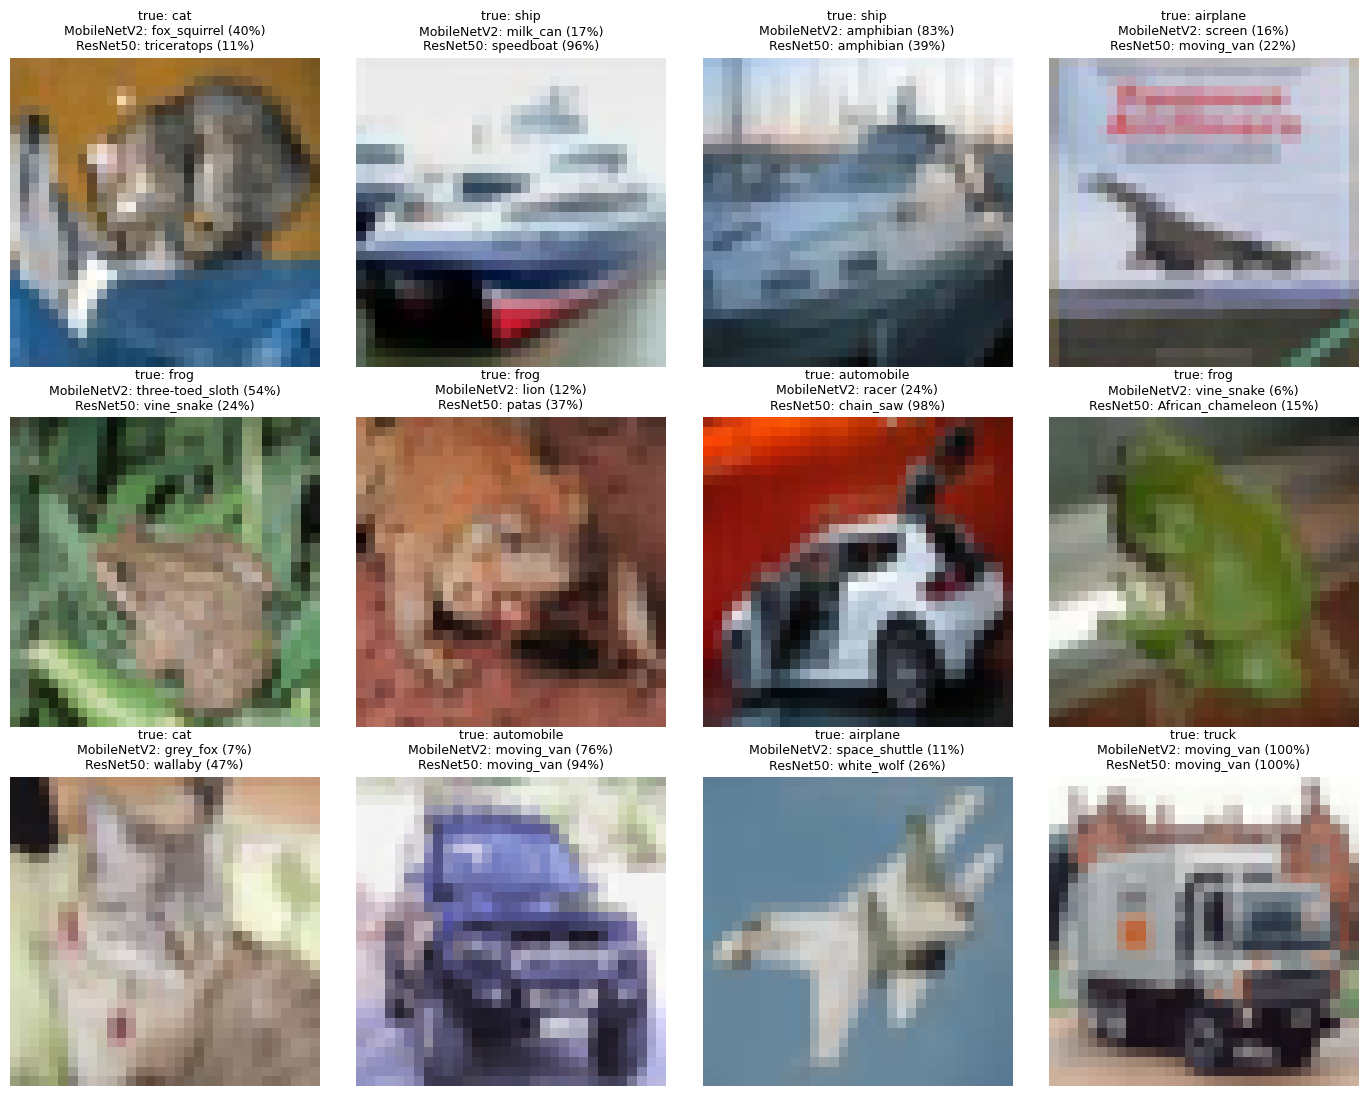

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i]); ax.axis("off")
    _, m_lab, m_p = pred_mobilenet[i][0]
    _, r_lab, r_p = pred_resnet[i][0]
    ax.set_title(f"true: {labels[y_test_int[i]]}\nMobileNetV2: {m_lab} ({m_p:.0%})\nResNet50: {r_lab} ({r_p:.0%})",
                 fontsize=9)
plt.tight_layout(); plt.show()

**Answer – does it work? No, not really.** The pipeline runs without error (correct input size, correct preprocessing, predictions decoded into ImageNet labels), but the predictions are mostly wrong or meaningless:

| # | True class | MobileNetV2 top-1 | ResNet50 top-1 | Verdict |
|---|---|---|---|---|
| 0 | cat | fox_squirrel (40 %) | triceratops (11 %) | ✘ |
| 1 | ship | milk_can (17 %) | speedboat (96 %) | ResNet ✔ |
| 2 | ship | amphibian (83 %) | amphibian (39 %) | ✘ (amphibious vehicle) |
| 3 | airplane | screen (16 %) | moving_van (22 %) | ✘ |
| 4 | frog | three-toed_sloth (54 %) | vine_snake (24 %) | ✘ (tailed_frog only in ResNet's top-3) |
| 5 | frog | lion (12 %) | patas (37 %) | ✘ |
| 6 | automobile | racer (24 %) | chain_saw (98 %) | MobileNet ≈ ✔ |
| 7 | frog | vine_snake (6 %) | African_chameleon (15 %) | ✘ |
| 8 | cat | grey_fox (7 %) | wallaby (47 %) | ✘ (Egyptian_cat in ResNet's top-3) |
| 9 | automobile | moving_van (76 %) | moving_van (94 %) | ≈ (a vehicle, wrong type) |
| 10 | airplane | space_shuttle (11 %) | white_wolf (26 %) | MobileNet ≈ ✔ |
| 11 | truck | moving_van (100 %) | moving_van (100 %) | ✔ |

Only about 3–4 images out of 12 get a sensible label from each model, often with a low probability, while our small custom CNN gets 86 % of the whole test set right. Two models that are excellent on ImageNet (top-1 ≈ 72 % for MobileNetV2, ≈ 75 % for ResNet50 over 1,000 classes) fail here, for three reasons:

1. **Resolution.** The images are 32 × 32 and are upscaled to 224 × 224. Upscaling does not add any detail: the network receives large, very blurry images, unlike the sharp photos it was trained on. Its filters look for textures and fine details (fur, eyes, wheels) that simply are not there. When it is confident, it is often confidently wrong (ResNet50: *chain_saw* 98 % for a red car).
2. **Different label sets.** ImageNet has 1,000 fine-grained classes (e.g. 120 dog breeds, *moving_van*, *speedboat*), not the 10 CIFAR classes. Even a "correct" answer must be mapped by hand: *speedboat* → ship, *moving_van* → truck. And some CIFAR images match nothing obvious, which pushes the model towards odd classes (*milk_can*, *screen*).
3. **Different data distribution.** CIFAR-10 images come from another source, with other framing and quality. As in Question 9, a model only works well on data that looks like what it was trained on.

To use these networks properly on CIFAR-10, the standard approach would be **transfer learning**: keep the pretrained convolutional base (`include_top=False`), add a new 10-class output layer, and fine-tune it on the CIFAR-10 training images (ideally with a larger input size). The pretrained features would then be adapted to our classes and our images.